# 04 · Fine-tune the face-quality model on the team's own photos (v2)

**Why.** v1 (`02_train_quality.ipynb`) was trained only on 64 px Kaggle crops. On real webcam frames it scores lower
than on Kaggle (median about 0.72 vs 0.78), so its data-chosen threshold of 0.78 refused most good webcam frames and the
app had to use a hand-picked 0.65. Measured in `.agents/FACE_QUALITY.md` §5.

**What this notebook does (everything runs here on Colab):**
1. **In-domain data.** The team's enrolment photos (`AppliedML/<person>/`: JPEG, PNG and iPhone HEIC, rotated from
   EXIF like the app's gallery; `fake_*` spoof test images are left out) are found with YuNet at the live-preview
   width (640 px), exactly like the app. Each photo gets `VARIANTS` synthetic damages (`damage.py`), applied to a
   preview-sized view of the face.
2. **Labels**, with the same rule as v1. The recogniser (`face_recognition` v1) embeds the crop the app gives it (the
   YuNet box + 0.1 margin) cut from the same, possibly damaged, image. The label is the cosine to the leave-one-out
   mean of that person's *other* clean photos, rescaled with v1's percentiles (`meta.json`).
3. **Split by person.** `TEST_PEOPLE` are never used for training or for choosing anything except the final threshold.
   They are also not the two people whose photos were used to pick 0.65 by hand.
4. **Fine-tune from v1 with augmentation.** Each batch is half team crops and half Kaggle crops, so the model keeps
   what it learned. Augmentation: random scale, shift and rotation of the framing (so the score stops depending on how
   the face is cut), horizontal flip, mild brightness / contrast / saturation jitter. Damage is not used as
   augmentation, because it changes the label.
5. **Evaluate.** Spearman with labels and an EDC-style curve on the held-out people, for v1, v2 and the heuristic, plus
   a Kaggle validation regression check. The **threshold is chosen on in-domain data** with v1's rule.
6. **Save** `face_quality_v2.pt` (does not overwrite v1), `results_v2.json` and `figures/v2_*.png`.

Inputs on Drive: `face_quality_colab/labels/` and `face_quality_colab/repo/` (as for 02/03), plus the team photos:
add a shortcut to the shared **AppliedML** folder in *My Drive* (right-click → Organise → Add shortcut), or copy the
five person folders to `face_quality_colab/team_photos/`.

In [1]:
import sys
try:
    import pillow_heif  # noqa: F401  (iPhone HEIC photos)
except ImportError:
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow-heif"], check=True)
import csv, json, os, sys, time, importlib.util
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/face_quality_colab")
    REPO, LABELS = BASE / "repo", BASE / "labels"
    TEAM_CANDIDATES = [Path("/content/drive/MyDrive/AppliedML"), BASE / "team_photos"]
except ImportError:
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".agents").is_dir())
    LABELS = REPO / "data" / "raw" / "face_quality" / "labels"
    TEAM_CANDIDATES = [REPO / "AppliedML"]
TEAM = next((p for p in TEAM_CANDIDATES if p.is_dir()), None)
assert TEAM is not None, f"team photos not found in {TEAM_CANDIDATES}: add the AppliedML shortcut to My Drive"
NOT_PEOPLE = {"student_card_image", "video data"}
import unicodedata
nfc = lambda t: unicodedata.normalize("NFC", t)   # Drive may store Vietnamese names decomposed (NFD)
PERSON_DIR = {nfc(p.name): p for p in TEAM.iterdir() if p.is_dir() and nfc(p.name) not in NOT_PEOPLE}
PEOPLE = sorted(PERSON_DIR)
TEST_PEOPLE = [nfc(t) for t in ("Hồng Minh", "Mai Chi")]         # held out; 0.65 was picked by hand on Minh Thành / Đức Mạnh
assert set(TEST_PEOPLE) <= set(PEOPLE), (TEST_PEOPLE, PEOPLE)

SEED, VARIANTS = 30082, 12
BASE, FACE_PX = 384, 160       # damage is applied on a 384 px view with the face box 160 px tall
EPOCHS, STEPS_PER_EPOCH, BATCH = 8, 150, 128     # half team, half Kaggle per batch
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY = 1e-4, 3e-4, 1e-4
rng = np.random.default_rng(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load(feature):
    spec = importlib.util.spec_from_file_location(feature, REPO / "ml" / feature / "infer.py")
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod
recogniser, quality = load("face_recognition"), load("live_face_scan")
sys.path.insert(0, str(REPO / "ml" / "live_face_scan"))
from damage import DAMAGES, damage
from heuristic import heuristic_score
assert hasattr(quality, "align_matrix"), "repo/ml/live_face_scan/infer.py on Drive is old: upload the current one"

YUNET = REPO / "ml" / "face_recognition" / "models" / "face_detection_yunet_2023mar.onnx"
if not YUNET.is_file():
    YUNET = Path("/content/face_detection_yunet_2023mar.onnx")
    if not YUNET.is_file():
        import urllib.request
        urllib.request.urlretrieve("https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/"
                                   "face_detection_yunet_2023mar.onnx", YUNET)
meta = json.loads((LABELS / "meta.json").read_text(encoding="utf-8"))
P1, P99 = meta["cosine_p1"], meta["cosine_p99"]
REC_THR = recogniser.threshold()
FIG = REPO / "ml" / "live_face_scan" / "figures"; FIG.mkdir(exist_ok=True)
print("device", device, "| team photos", TEAM, "| people", PEOPLE, "| test", TEST_PEOPLE, "| recogniser threshold", round(REC_THR, 4))

Mounted at /content/drive
device cuda | team photos /content/drive/MyDrive/AppliedML | people ['Hồng Minh', 'Mai Chi', 'Minh Thành', 'Thuận Minh', 'Đức Mạnh'] | test ['Hồng Minh', 'Mai Chi'] | recogniser threshold 0.6922


## 1. Team crops, damage and labels

The detection mirrors the app (`backend/app/services/enrol.py`): YuNet on a copy at most 640 px wide, keeping the
largest face. Each photo becomes an unrotated 384 px view with the face box 160 px tall, about the size of a face in
the 640 px live preview, and the damage is applied to that view. From the same (possibly damaged) view, the quality
input is cut with `infer.align_crop` and the recogniser input with the app's `crop_face` rule (the box + 10 %, not
rotated). So each label describes exactly the image the model is scored on.

In [2]:
det = cv2.FaceDetectorYN.create(str(YUNET), "", (320, 320), 0.6)

def detect(img, width=640):
    k = min(1.0, width / img.shape[1])
    small = img if k == 1.0 else cv2.resize(img, (round(img.shape[1] * k), round(img.shape[0] * k)), interpolation=cv2.INTER_AREA)
    det.setInputSize((small.shape[1], small.shape[0]))
    _, f = det.detect(small)
    if f is None or not len(f):
        return None
    f = max(f, key=lambda r: r[2] * r[3])
    return f[:4] / k, [(f[4 + 2 * i] / k, f[5 + 2 * i] / k) for i in range(5)]

def base_image(img, box, marks):
    """Unrotated BASE x BASE view of the face, scaled so the YuNet box is FACE_PX tall (a face in the 640 px preview).
    Damage is applied here; both model inputs are then cut from it exactly as the app cuts them from a frame."""
    k = FACE_PX / box[3]
    ex, ey = (marks[0][0] + marks[1][0]) / 2, (marks[0][1] + marks[1][1]) / 2
    m = np.array([[k, 0, BASE * 0.5 - k * ex], [0, k, BASE * 0.45 - k * ey]])
    b = cv2.warpAffine(img, m, (BASE, BASE), flags=cv2.INTER_AREA if k < 1 else cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    pt = lambda x, y: (k * x + m[0, 2], k * y + m[1, 2])
    x, y = pt(box[0], box[1])
    return b, (x, y, box[2] * k, box[3] * k), [pt(*q) for q in marks]

def recog_crop(b, box, margin=0.1):
    """backend/app/core/ml_models.crop_face(image, box, "face_recognition"): the box + 10 % margin, not rotated."""
    x, y, w, h = box
    x0, y0 = int(max(0, x - w * margin)), int(max(0, y - h * margin))
    x1, y1 = int(min(b.shape[1], x + w * (1 + margin))), int(min(b.shape[0], y + h * (1 + margin)))
    return b[y0:y1, x0:x1]

def read_photo(path, max_side=1600):
    """Same as backend/app/services/gallery.py: JPEG / PNG / HEIC, rotated upright from EXIF, at most 1600 px."""
    from PIL import Image, ImageOps
    from pillow_heif import register_heif_opener
    register_heif_opener()
    rgb = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    rgb.thumbnail((max_side, max_side))
    return np.asarray(rgb)[:, :, ::-1].copy()

PHOTO_EXT = {".jpg", ".jpeg", ".png", ".heic", ".heif"}
kinds = list(DAMAGES)
samples, skipped = [], []      # one dict per crop (clean or damaged)
for person in PEOPLE:
    files = sorted(f for f in PERSON_DIR[person].iterdir()
                   if f.suffix.lower() in PHOTO_EXT and not f.name.lower().startswith("fake"))   # fake_* = spoof test images
    for f in files:
        try:
            img = read_photo(f)
        except Exception as e:  # noqa: BLE001
            skipped.append(f"{person}/{f.name} ({e})"); continue
        found = detect(img)
        if found is None:
            skipped.append(f"{person}/{f.name}"); continue
        b, bbox, bmarks = base_image(img, *found)
        versions = [("clean", 0.0, b)] + [(k, lv, damage(b, k, lv, rng)) for k, lv in
                    zip(rng.choice(kinds, VARIANTS), rng.uniform(0.1, 0.9, VARIANTS))]
        for kind, level, im in versions:
            samples.append(dict(person=person, photo=f.name, damage=str(kind), level=float(level),
                                image=quality.align_crop(im, bmarks),          # what the app feeds the quality model
                                emb=recogniser.embed(recog_crop(im, bbox)),     # what the app feeds the recogniser
                                face_px=float(bbox[3])))
print({p: sum(s['person'] == p and s['damage'] == 'clean' for s in samples) for p in PEOPLE}, 'clean photos per person')
print(f"{len(samples)} crops from {len(samples) // (VARIANTS + 1)} photos; no face found in {len(skipped)}: {skipped}")

# label = cosine to the leave-one-out mean of the person's OTHER clean photos (rule of 01_build_labels), v1 percentiles
for person in PEOPLE:
    clean = {s["photo"]: s["emb"] for s in samples if s["person"] == person and s["damage"] == "clean"}
    for s in samples:
        if s["person"] != person:
            continue
        others = [e for p, e in clean.items() if p != s["photo"]]
        c = np.mean(others, 0); c /= np.linalg.norm(c)
        s["cos"] = float(s["emb"] @ c)
        s["label"] = float(np.clip((s["cos"] - P1) / (P99 - P1), 0, 1))
team_x = np.stack([s["image"] for s in samples])
team_y = np.array([s["label"] for s in samples], np.float32)
team_cos = np.array([s["cos"] for s in samples], np.float32)
team_kind = np.array([s["damage"] for s in samples])
team_test = np.array([s["person"] in TEST_PEOPLE for s in samples])
team_tr, team_te = np.where(~team_test)[0], np.where(team_test)[0]

def spearman(a, b):
    ra, rb = np.argsort(np.argsort(a)), np.argsort(np.argsort(b))
    return float(np.corrcoef(ra, rb)[0, 1])

print(f"train {len(team_tr)} crops ({sorted(set(PEOPLE) - set(TEST_PEOPLE))}) | test {len(team_te)} crops ({TEST_PEOPLE})")
print(f"mean label: clean {team_y[team_kind == 'clean'].mean():.3f}, damaged {team_y[team_kind != 'clean'].mean():.3f}; "
      f"clean cosine median {np.median(team_cos[team_kind == 'clean']):.3f} (recogniser threshold {REC_THR:.3f})")
lv = np.array([s["level"] for s in samples])
for k in kinds:
    i = team_kind == k
    print(f"  {k:10s} n {i.sum():4d}  mean label {team_y[i].mean():.3f}  Spearman(label, level) {spearman(team_y[i], lv[i]):+.2f}")

{'Hồng Minh': 13, 'Mai Chi': 13, 'Minh Thành': 27, 'Thuận Minh': 28, 'Đức Mạnh': 14} clean photos per person
1235 crops from 95 photos; no face found in 13: ['Hồng Minh/1795579393164_6100167967681657445_6100167967681657445_d521d8e0361e2a498baeced1b799eba1.jpg', 'Hồng Minh/IMG_8113.HEIC', 'Hồng Minh/IMG_8115.HEIC', 'Hồng Minh/IMG_8116.HEIC', 'Mai Chi/81a06e89-3cc6-40b0-bdd4-1220092fb06b.jpeg', 'Mai Chi/e25a103f-76df-4464-9e15-d2d175b0288f.jpeg', 'Minh Thành/WIN_20261120_22_58_23_Pro.jpg', 'Thuận Minh/1795579318272_281883942865513508_2633278266964502854_d1643287e7f8265ed8ea66f506ba9a2d.jpg', 'Thuận Minh/1795579318301_281883942865513508_2633278266964502854_f05de8f3d21122b19033dd031d2dd90d.jpg', 'Thuận Minh/1795579318340_281883942865513508_2633278266964502854_6c4c8b8920875570c45b14bc8f38004f.jpg', 'Thuận Minh/IMG_20261120_223149.jpg', 'Thuận Minh/IMG_20261120_223150.jpg', 'Thuận Minh/IMG_20261120_223154.jpg']
train 897 crops (['Minh Thành', 'Thuận Minh', 'Đức Mạnh']) | test 338 crops (['Hồ

In [3]:
# a look at the data (team faces: shown here only, not saved to the repo)
show = list(team_te[:: max(1, len(team_te) // 12)])[:12]
fig, ax = plt.subplots(1, len(show), figsize=(2 * len(show), 2.4))
for a_, i in zip(ax, show):
    a_.imshow(team_x[i][..., ::-1]); a_.set_title(f"{team_kind[i]}\nlabel {team_y[i]:.2f}", fontsize=8); a_.axis("off")
plt.tight_layout(); plt.show()

## 2. Kaggle data (kept in every batch so the model does not forget it)

In [4]:
k_images = np.load(LABELS / "images.npy")
k_rows = list(csv.DictReader((LABELS / "labels.csv").open(encoding="utf-8")))
k_y = np.array([float(r["label"]) for r in k_rows], np.float32)
k_split = np.array([r["split"] for r in k_rows])
k_tr, k_va = np.where(k_split == "train")[0], np.where(k_split == "val")[0]
print(f"Kaggle train {len(k_tr)} / val {len(k_va)}")

MEAN = torch.tensor(quality.MEAN, device=device).view(1, 3, 1, 1); STD = torch.tensor(quality.STD, device=device).view(1, 3, 1, 1)
S = quality.INPUT_SIZE

def to_tensor(arr):
    x = torch.from_numpy(np.ascontiguousarray(arr[..., ::-1])).permute(0, 3, 1, 2).float().to(device) / 255
    return F.interpolate(x, size=(S, S), mode="bilinear", align_corners=False, antialias=True)

def augment(x):
    """Framing (scale 0.88-1.12, shift +-6 %, rotation +-8 deg), flip, mild colour jitter. Label-preserving."""
    n = len(x)
    s = torch.empty(n, device=device).uniform_(0.88, 1.12)
    r = torch.empty(n, device=device).uniform_(-8, 8) * np.pi / 180
    t = torch.empty(n, 2, device=device).uniform_(-0.12, 0.12)          # grid units: 0.12 = 6 % of the side
    theta = torch.stack([torch.stack([torch.cos(r) / s, -torch.sin(r) / s, t[:, 0]], 1),
                         torch.stack([torch.sin(r) / s, torch.cos(r) / s, t[:, 1]], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
    flip = torch.rand(n, device=device) < 0.5
    x[flip] = x[flip].flip(-1)
    b = torch.empty(n, 1, 1, 1, device=device).uniform_(0.85, 1.15)
    c = torch.empty(n, 1, 1, 1, device=device).uniform_(0.85, 1.15)
    g = x.mean((1, 2, 3), keepdim=True)
    x = (x - g) * c + g * b
    grey = x.mean(1, keepdim=True)
    sat = torch.empty(n, 1, 1, 1, device=device).uniform_(0.8, 1.2)
    return (grey + (x - grey) * sat).clamp(0, 1)

def norm(x):
    return ((x - MEAN) / STD).contiguous()

Kaggle train 19200 / val 4800


## 3. Fine-tune from v1

In [5]:
v1 = torch.load(REPO / "ml" / "live_face_scan" / "live_face_scan.pt", map_location="cpu", weights_only=True)
model = quality.build_model().to(device)
model.load_state_dict(v1["state_dict"])
v1_model = quality.build_model().to(device); v1_model.load_state_dict(v1["state_dict"]); v1_model.eval()

head = list(model.classifier.parameters()); head_ids = {id(p) for p in head}
opt = torch.optim.AdamW([{"params": [p for p in model.parameters() if id(p) not in head_ids], "lr": LR_BACKBONE},
                         {"params": head, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_BACKBONE, LR_HEAD], total_steps=EPOCHS * STEPS_PER_EPOCH, pct_start=0.15)
loss_fn = nn.HuberLoss(delta=0.1)

def predict(net, arr):
    net.eval(); out = []
    with torch.inference_mode():
        for i in range(0, len(arr), 512):
            out.append(net(norm(to_tensor(arr[i:i + 512])))[:, 0].float().cpu().numpy())
    return np.concatenate(out)

k_va_s = rng.choice(k_va, min(2000, len(k_va)), replace=False)       # fixed Kaggle check subset
history = []
for epoch in range(1, EPOCHS + 1):
    t0, total = time.time(), 0.0
    model.train()
    for _ in range(STEPS_PER_EPOCH):
        it, ik = rng.choice(team_tr, BATCH // 2), rng.choice(k_tr, BATCH // 2)
        x = augment(torch.cat([to_tensor(team_x[it]), to_tensor(k_images[ik])]))
        t = torch.from_numpy(np.concatenate([team_y[it], k_y[ik]])).to(device)
        loss = loss_fn(model(norm(x))[:, 0], t)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); total += loss.item()
    h = dict(epoch=epoch, train_loss=total / STEPS_PER_EPOCH,
             team_train_spearman=spearman(predict(model, team_x[team_tr]), team_y[team_tr]),
             kaggle_val_spearman=spearman(predict(model, k_images[k_va_s]), k_y[k_va_s]),
             team_test_spearman=spearman(predict(model, team_x[team_te]), team_y[team_te]),   # watched, never used to choose
             seconds=time.time() - t0)
    history.append(h)
    print(f"epoch {epoch}  loss {h['train_loss']:.4f}  team-train {h['team_train_spearman']:.3f}  "
          f"Kaggle-val {h['kaggle_val_spearman']:.3f}  team-test {h['team_test_spearman']:.3f}  ({h['seconds']:.0f} s)")
print("the last epoch is kept (fixed schedule; nothing is selected on the test people)")

epoch 1  loss 0.0075  team-train 0.835  Kaggle-val 0.713  team-test 0.603  (12 s)
epoch 2  loss 0.0055  team-train 0.906  Kaggle-val 0.718  team-test 0.615  (9 s)
epoch 3  loss 0.0048  team-train 0.930  Kaggle-val 0.719  team-test 0.605  (10 s)
epoch 4  loss 0.0045  team-train 0.945  Kaggle-val 0.722  team-test 0.631  (9 s)
epoch 5  loss 0.0044  team-train 0.952  Kaggle-val 0.724  team-test 0.625  (10 s)
epoch 6  loss 0.0042  team-train 0.954  Kaggle-val 0.724  team-test 0.618  (10 s)
epoch 7  loss 0.0041  team-train 0.956  Kaggle-val 0.725  team-test 0.623  (9 s)
epoch 8  loss 0.0041  team-train 0.957  Kaggle-val 0.725  team-test 0.621  (9 s)
the last epoch is kept (fixed schedule; nothing is selected on the test people)


## 4. Evaluation on the held-out people

- **Spearman** between score and label on the test people (clean and damaged together, then clean only).
- **EDC-style curve.** A crop is a *recognition failure* when its cosine to the person's mean is below the recogniser's
  threshold. This is crop-vs-gallery, the way the app matches, rather than Kaggle's pairs. Discarding the
  lowest-scored crops first should lower the failure rate among the crops kept.
- **Kaggle regression check**: v2 must not get much worse than v1 on Kaggle validation.

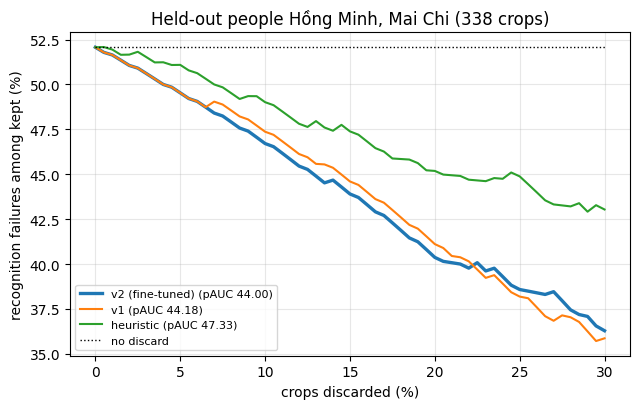

v2 (fine-tuned)  Spearman +0.621  (clean only +0.070)  EDC pAUC 44.00
v1               Spearman +0.583  (clean only -0.031)  EDC pAUC 44.18
heuristic        Spearman +0.241  (clean only -0.013)  EDC pAUC 47.33
Kaggle val Spearman: v1 0.723 -> v2 0.725
per damage type on the test people (Spearman score vs label):
  clean      n  26  v1 -0.03  v2 +0.07  mean v1 0.68 v2 0.69
  blur       n  37  v1 +0.30  v2 +0.06  mean v1 0.49 v2 0.55
  motion     n  41  v1 +0.24  v2 +0.50  mean v1 0.39 v2 0.45
  noise      n  32  v1 +0.59  v2 +0.77  mean v1 0.49 v2 0.37
  jpeg       n  29  v1 +0.04  v2 +0.15  mean v1 0.68 v2 0.65
  downscale  n  39  v1 -0.03  v2 +0.03  mean v1 0.70 v2 0.72
  dark       n  42  v1 +0.50  v2 +0.44  mean v1 0.60 v2 0.60
  bright     n  30  v1 +0.54  v2 +0.57  mean v1 0.51 v2 0.57
  occlusion  n  36  v1 +0.73  v2 +0.79  mean v1 0.37 v2 0.45
  pose       n  26  v1 +0.25  v2 +0.41  mean v1 0.61 v2 0.67


In [6]:
Xte, yte, cte, kte = team_x[team_te], team_y[team_te], team_cos[team_te], team_kind[team_te]
fail = cte < REC_THR
s1, s2 = predict(v1_model, Xte), predict(model, Xte)
sh = np.array([heuristic_score(cv2.resize(im, (112, 112)), samples[i]["face_px"]) for im, i in zip(Xte, team_te)])
scores = {"v2 (fine-tuned)": s2, "v1": s1, "heuristic": sh}

def edc(score, fail, max_discard=0.30, steps=61):
    order = np.argsort(score)
    xs = np.linspace(0, max_discard, steps)
    ys = np.array([fail[order[int(round(x * len(score))):]].mean() for x in xs])
    return xs, ys, float(getattr(np, "trapezoid", getattr(np, "trapz", None))(ys, xs) / max_discard)

res = {"test_people": TEST_PEOPLE, "n_test": int(len(team_te)), "n_train_team": int(len(team_tr)),
       "failure_rate_at_0": float(fail.mean()), "recogniser_threshold": REC_THR, "methods": {}}
clean = kte == "clean"
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for name, s in scores.items():
    xs, ys, pauc = edc(s, fail)
    ax.plot(xs * 100, ys * 100, lw=2.4 if name.startswith("v2") else 1.5, label=f"{name} (pAUC {pauc * 100:.2f})")
    res["methods"][name] = dict(spearman=spearman(s, yte), spearman_clean=spearman(s[clean], yte[clean]), pAUC_0_30=pauc)
ax.plot(xs * 100, [fail.mean() * 100] * len(xs), "k:", lw=1, label="no discard")
ax.set_xlabel("crops discarded (%)"); ax.set_ylabel("recognition failures among kept (%)")
ax.set_title(f"Held-out people {', '.join(TEST_PEOPLE)} ({len(team_te)} crops)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "v2_edc_team.png", dpi=130); plt.show()

kv = predict(model, k_images[k_va_s]); kv1 = predict(v1_model, k_images[k_va_s])
res["kaggle_val_spearman"] = {"v1": spearman(kv1, k_y[k_va_s]), "v2": spearman(kv, k_y[k_va_s]), "n": int(len(k_va_s))}
for name, r in res["methods"].items():
    print(f"{name:16s} Spearman {r['spearman']:+.3f}  (clean only {r['spearman_clean']:+.3f})  EDC pAUC {r['pAUC_0_30'] * 100:.2f}")
print(f"Kaggle val Spearman: v1 {res['kaggle_val_spearman']['v1']:.3f} -> v2 {res['kaggle_val_spearman']['v2']:.3f}")
print("per damage type on the test people (Spearman score vs label):")
for k in ["clean", *kinds]:
    i = kte == k
    if i.sum() > 3:
        print(f"  {k:10s} n {i.sum():3d}  v1 {spearman(s1[i], yte[i]):+.2f}  v2 {spearman(s2[i], yte[i]):+.2f}  mean v1 {s1[i].mean():.2f} v2 {s2[i].mean():.2f}")

## 5. Threshold, chosen on in-domain data

v1's rule, applied to the held-out team crops: the lowest *t* at which the failure rate among crops scoring ≥ *t* is
at most 1.1 × the failure rate of the clean crops. This answers "keep a frame only if it is about as good for
recognition as a clean photo".

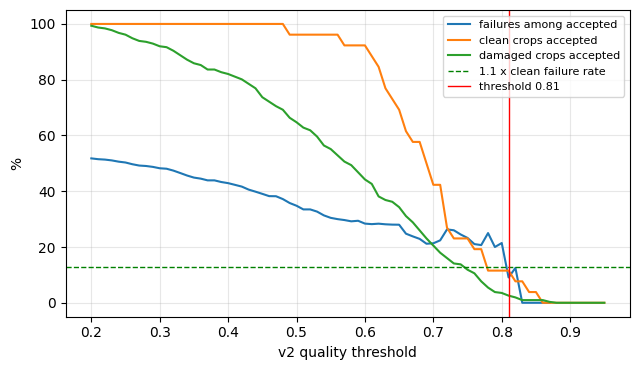

threshold 0.81 (lowest t with failure rate(score >= t) <= 1.1 x clean failure rate, on held-out team crops)
accepts 12% of clean held-out crops; by damage: {'clean': '12%', 'blur': '0%', 'motion': '0%', 'noise': '0%', 'jpeg': '7%', 'downscale': '13%', 'dark': '0%', 'bright': '3%', 'occlusion': '0%', 'pose': '0%'}
v1 at its own 0.78 accepts 23% and at the app's 0.65 54% of the same clean crops


In [7]:
target = 1.1 * fail[clean].mean() if fail[clean].any() else 0.0
ts = np.round(np.arange(0.20, 0.96, 0.01), 2)
rows = []
for t in ts:
    acc = s2 >= t
    rows.append((t, fail[acc].mean() if acc.any() else np.nan, acc[clean].mean(), acc[~clean].mean()))
ok = [r for r in rows if not np.isnan(r[1]) and r[1] <= target + 1e-9 and r[2] > 0]
thr = float(ok[0][0]) if ok else float(np.median(s2[clean]))
rule = ("lowest t with failure rate(score >= t) <= 1.1 x clean failure rate, on held-out team crops" if ok else
        "fallback: median v2 score of clean held-out crops (rule had no solution)")
acc = s2 >= thr
res["threshold"] = dict(value=thr, rule=rule, target_failure=float(target), clean_failure=float(fail[clean].mean()),
                        accepted_clean=float(acc[clean].mean()),
                        accepted_by_damage={k: float(acc[kte == k].mean()) for k in ["clean", *kinds] if (kte == k).any()})
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot([r[0] for r in rows], [r[1] * 100 for r in rows], label="failures among accepted")
ax.plot([r[0] for r in rows], [r[2] * 100 for r in rows], label="clean crops accepted")
ax.plot([r[0] for r in rows], [r[3] * 100 for r in rows], label="damaged crops accepted")
ax.axhline(target * 100, color="g", ls="--", lw=1, label="1.1 x clean failure rate"); ax.axvline(thr, color="r", lw=1, label=f"threshold {thr:.2f}")
ax.set_xlabel("v2 quality threshold"); ax.set_ylabel("%"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "v2_threshold.png", dpi=130); plt.show()
print(f"threshold {thr:.2f} ({rule})")
print(f"accepts {acc[clean].mean():.0%} of clean held-out crops; by damage:",
      {k: f"{v:.0%}" for k, v in res["threshold"]["accepted_by_damage"].items()})
print("v1 at its own 0.78 accepts", f"{(s1[clean] >= 0.78).mean():.0%}", "and at the app's 0.65", f"{(s1[clean] >= 0.65).mean():.0%}", "of the same clean crops")

## 6. Save v2 (v1 stays untouched)

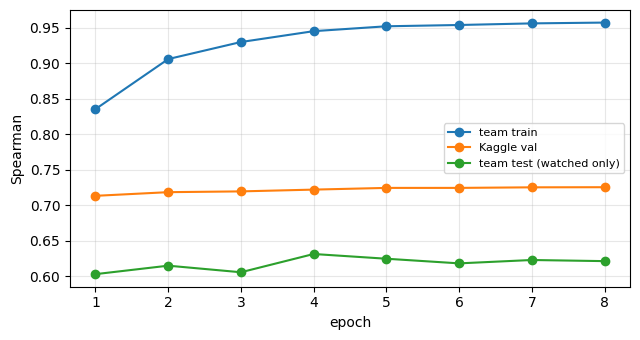

saved face_quality_v2.pt (4.4 MB), results_v2.json, figures v2_*.png
check through infer.py: 0.7709 vs 0.7709 | threshold 0.81


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
e = [h["epoch"] for h in history]
for k, lab in (("team_train_spearman", "team train"), ("kaggle_val_spearman", "Kaggle val"), ("team_test_spearman", "team test (watched only)")):
    ax.plot(e, [h[k] for h in history], marker="o", label=lab)
ax.set_xlabel("epoch"); ax.set_ylabel("Spearman"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "v2_training.png", dpi=130); plt.show()

payload = {k: v for k, v in v1.items() if k not in ("state_dict", "history")}
payload.update(state_dict={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
               threshold=thr, threshold_status=f"chosen in 04_finetune_team.ipynb: {rule}", threshold_domain="webcam",
               version="v2", parent="v1", history=history,
               training=dict(v1["training"], v2=dict(seed=SEED, epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH, batch=BATCH,
                   mix="half team / half Kaggle per batch", lr_backbone=LR_BACKBONE, lr_head=LR_HEAD,
                   augmentation="framing scale 0.88-1.12, shift +-6 %, rotation +-8 deg, flip, brightness/contrast 0.85-1.15, saturation 0.8-1.2",
                   team_train_people=sorted(set(PEOPLE) - set(TEST_PEOPLE)), team_test_people=TEST_PEOPLE,
                   team_variants=VARIANTS, base=BASE, face_px=FACE_PX, init="face_quality v1", device=str(device))))
out = REPO / "ml" / "live_face_scan" / "face_quality_v2.pt"
torch.save(payload, out)
res["history"] = history
(REPO / "ml" / "live_face_scan" / "results_v2.json").write_text(json.dumps(res, indent=1, ensure_ascii=False), encoding="utf-8")
os.environ["HAWKEYE_LIVE_FACE_SCAN_WEIGHTS"] = str(out); quality._state.clear()
print(f"saved {out.name} ({out.stat().st_size / 1e6:.1f} MB), results_v2.json, figures v2_*.png")
print("check through infer.py:", round(quality.score(Xte[0]), 4), "vs", round(float(s2[0]), 4), "| threshold", quality.threshold())